# WP13 v1.1 — Kaynak pasajından yan etki adayına

Önceki v1 kodu değişmedi; ayrı v1.1 entrypoint/modül. Bu notebook yalnız yeni QA dosyaları ve gerçek kaynaklardan hesaplanan tabloları gösterir; API veya eğitim yok. Aday çıkarımı WP12 sonuçları değildir, insan onayı PENDING.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/v1_1';F=ROOT/'reports/figures/WP13/v1_1'
read=lambda n:json.loads((Q/n).read_text(encoding='utf-8'))
display(pd.read_csv(Q/'source_cohort_summary.csv'))


,filename,parent,pages,accepted_quotes,candidate_rows,candidates_with_saved_explanation,gnn_PT,gnn_outer_fold,all_candidate_review,MedDRA_candidate_mapping
0,pil.502.pdf,DB00199,6,12,34,8,318,3,PENDING,UNMAPPED
1,050641Orig1s032lbl.pdf,DB00254,11,32,34,1,240,1,PENDING,UNMAPPED


**Yorum:** Her iki PDF’de34kaynak-bağlı aday; bunlar benzersiz klinik yan etki veya bağımsız kanıt sayısı değildir. Aynı ilaç/sınıf kapsamı ayrımları korunur. İki PDF/44alıntı değişmedi; MedDRA eşleme UNMAPPED.

In [2]:

t=pd.read_csv(Q/'candidate_records.csv')
display(t[['name_tr','frequency','scope','physical_page','quote_id','quote_start','quote_end','status','MedDRA_mapping']])
with pd.option_context('display.max_colwidth',None):
 display(t[t.source_key.eq('D_class_renal')][['name_tr','quote_exact','context_quotes']])


,name_tr,frequency,scope,physical_page,quote_id,quote_start,quote_end,status,MedDRA_mapping
0,Nefes almada güçlük,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
1,Bayılma,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
2,"Yüz, dudak veya boğaz şişmesi",NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
3,Deri döküntüleri,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
4,Büyük sıvı dolu kabarcıklar,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
5,Yaralar ve ülserler,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
6,Ağız ve boğaz ülserleri,NOT_SPECIFIED,product_specific,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,1640,2087,CANDIDATE_PENDING_HUMAN,UNMAPPED
7,İshal,NOT_SPECIFIED,product_specific,5,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85,0,2371,CANDIDATE_PENDING_HUMAN,UNMAPPED
8,Stevens–Johnson sendromu,NOT_SPECIFIED,product_specific,5,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85,0,2371,CANDIDATE_PENDING_HUMAN,UNMAPPED
9,Toksik epidermal nekroliz,NOT_SPECIFIED,product_specific,5,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85,0,2371,CANDIDATE_PENDING_HUMAN,UNMAPPED


,name_tr,quote_exact,context_quotes
54,BUN artışı,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,"[{""quote_id"": ""quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48"", ""document_id"": ""sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5"", ""extraction_run_id"": ""run:f6213756b1955f836f983cbe95a83f69a9c9d391d3df45b2c50dcd25ba333ea5"", ""page_id"": ""page:17a079d6611bef41f4e1f625ed2fb32f512acdf19d29d252840a38bd77153aff"", ""page_number"": 7, ""char_start"": 210, ""char_end"": 299, ""quote"": ""The following adverse reactions have been observed in patients receiving tetracyclines. \n"", ""quote_sha256"": ""d22535582611ca1e18c15bcbdf79934ff47b2847a54fad42090582f56ab81843"", ""claim_kind"": ""verbatim_source_quote"", ""purpose"": ""scope_anchor"", ""scope"": ""class_level"", ""qualifier"": ""Governs following ADR subsections;not drug-specific proof""}, {""quote_id"": ""quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b"", ""document_id"": ""sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5"", ""extraction_run_id"": ""run:f6213756b1955f836f983cbe95a83f69a9c9d391d3df45b2c50dcd25ba333ea5"", ""page_id"": ""page:8cbb4a4c0bfb096ade2d4e4e43f5cb9ef7cd8278583be6c9a4e8a312cee8c594"", ""page_number"": 4, ""char_start"": 3826, ""char_end"": 4023, ""quote"": ""The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indicate that this does not occur \nwith the use of doxycycline in patients with impaired renal function. \n"", ""quote_sha256"": ""b3056768608d12c0af518a314d9aa152789c1d823075d087ce0944980e5960ee"", ""claim_kind"": ""verbatim_source_quote"", ""purpose"": ""warning"", ""scope"": ""class_statement_with_doxycycline_exception"", ""qualifier"": ""Retain BOTH sentences;doxycycline exception in renal-impairment context;not positive doxycycline-BUN label""}]"


**Yorum:** UNKNOWN, infrequent, Rare instances, uncommon ve NOT_SPECIFIED birbirinin yerine geçirilmez. BUN kaydı sınıf düzeyindedir; renal işlev/doxycycline istisnasının iki orijinal cümlesi ayrıca bağlıdır. Yeni PDF taraması sonlu sözlük + başlık kuralıdır; genel klinik NLP değildir.

In [3]:

display(pd.DataFrame(read('GNN_provenance_checks.json')))
display(pd.read_csv(Q/'GNN_DB00254_recorded.csv').head(12))


,filename,parent,outer_fold,targets,model_version,job_keys,validation
0,pil.502.pdf,DB00199,3,318,WP10-molecular-protein-factorial-observed-record-training-v1,[primary_o03_final_A1P1],OOF/source hash + model metadata/NPZ manifest verified; no weights loaded for inference
1,050641Orig1s032lbl.pdf,DB00254,1,240,WP10-molecular-protein-factorial-observed-record-training-v1,[primary_o01_final_A1P1],OOF/source hash + model metadata/NPZ manifest verified; no weights loaded for inference


,class_id,score_observed_record_proxy,model_job_key,target_name
0,C0027497,0.971336,primary_o01_final_A1P1,Nausea
1,C0011603,0.960591,primary_o01_final_A1P1,Dermatitis
2,C0033774,0.954618,primary_o01_final_A1P1,Pruritus
3,C0042963,0.954511,primary_o01_final_A1P1,Vomiting
4,C0015230,0.949093,primary_o01_final_A1P1,Rash
5,C0011991,0.942400,primary_o01_final_A1P1,Diarrhoea
6,C0014457,0.898638,primary_o01_final_A1P1,Eosinophilia
7,C0002792,0.880323,primary_o01_final_A1P1,Anaphylactic shock
8,C0040034,0.868520,primary_o01_final_A1P1,Thrombocytopenia
9,C0042109,0.868070,primary_o01_final_A1P1,Urticaria


**GNN yorumu:** Erythromycin outer3/318PT, Doxycycline outer1/240PT kayıtlı OOF; JSON/NPZ hash ve job kimlikleri doğrulandı. İsimler mevcut CUI sözlüğündendir; PDF adaylarıyla otomatik eşleştirilmez. Skor klinik risk veya bireysel olasılık değildir.

In [4]:

display(pd.DataFrame([read('test_summary_final.json'),read('launcher_parse_hash.json')]))
display(pd.DataFrame([read('browser_verification.json')]).T)
print('AppTest durumu:',read('app_test_status.json'))


AppTest durumu: {'status': 'TIMED_OUT_45_SECONDS_NO_RETRY'}


,tests,returncode,new_API_requests,additional_model_provenance_checks,errors,executed,sha256
0,20.0,0.0,0.0,True,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,0.0,False,85997b16ed1c121c7789ebfd51cbdba13eec79180423c302f27bb81afcbfcd7e


,0
URL,http://127.0.0.1:8502
reason_for_QA_port,Original v1 server on8501 preserved; launcher default8501
Erythromycin_candidate_count,34
Doxycycline_candidate_count,34
actual_row_click_Glossit_source,PASS
source_page,7
source_quote_range,"[299, 889]"
selected_term_range,"[355, 364]"
clicked_row_replay_absent_NOT_AVAILABLE,PASS
selected_Bayilma_S04_replay_with_warning,PASS


**Test yorumu:**20veri/yöntem testi PASS. AppTest ilk dosya-yolu hatası düzeltildi; sonraki45saniye zaman aşımı başarı sayılmadı ve tekrar edilmedi. Gerçek browser satır tıklaması, kaynak/istisna, koşullu açıklama ve yeni yükleme ayrı kanıtlardır. Kullanılan port8502 yalnız v1’i bozmadan QA içindir; launcher varsayılan8501.

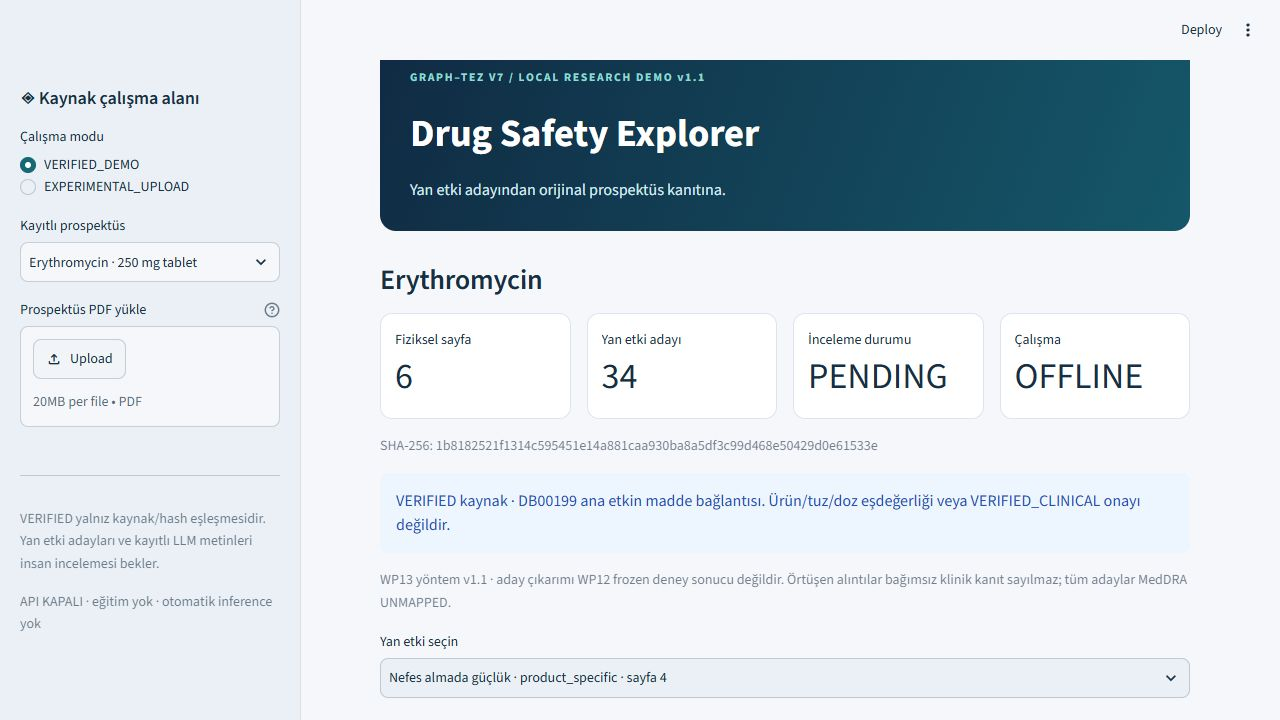

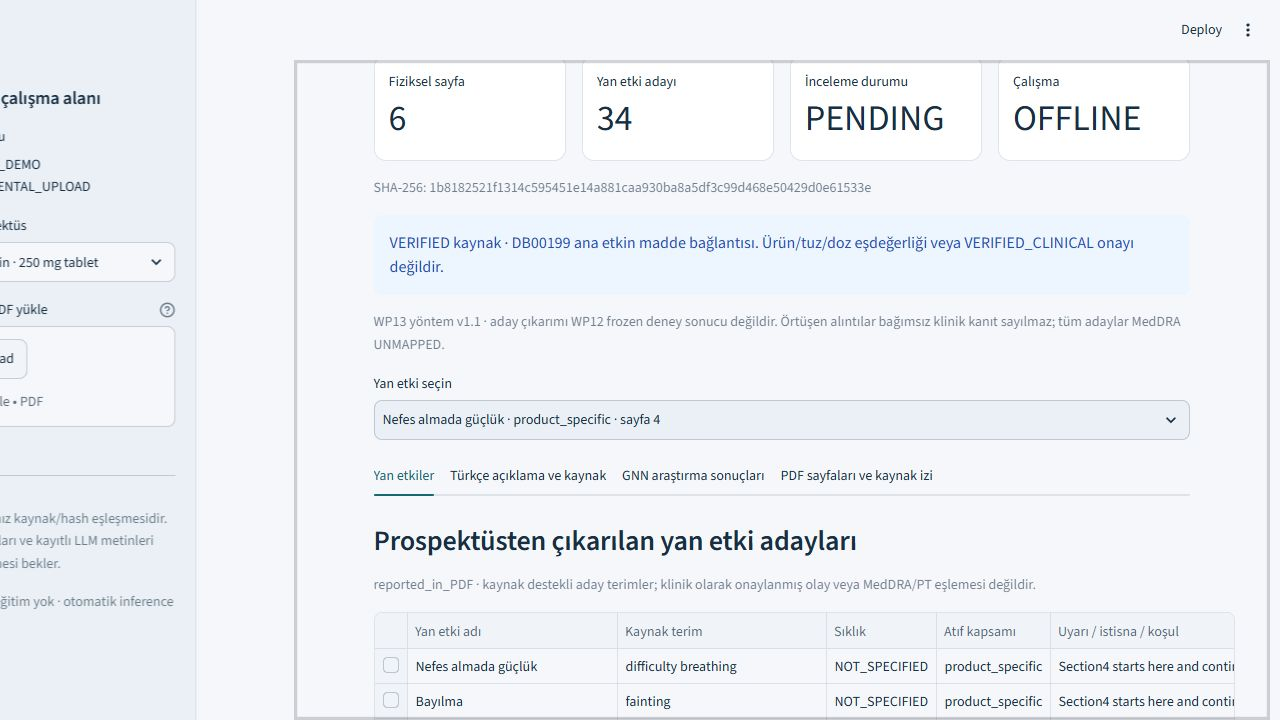

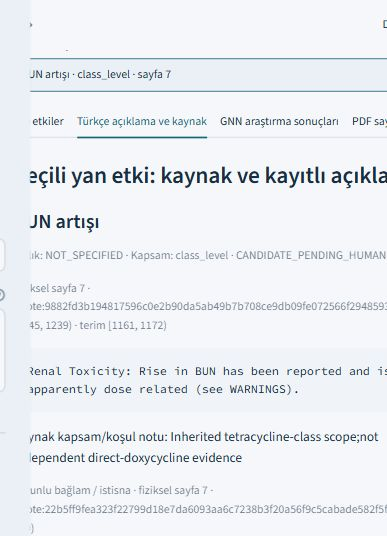

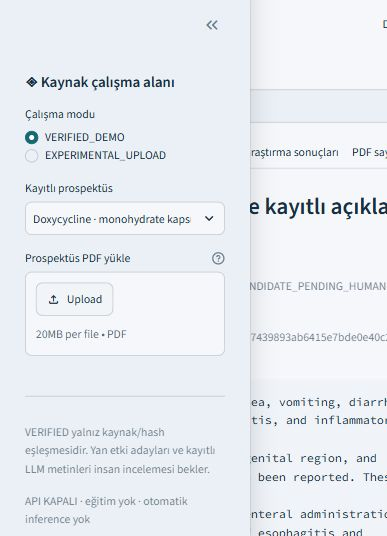

In [5]:

from IPython.display import Image
for n in ['01_erythromycin_overview.jpg','02_erythromycin_adverse_table.jpg','05_doxycycline_BUN_exception.jpg','08_uncovered_effect_no_explanation.jpg']:
 display(Image(filename=str(F/n)))


**Görsel yorumu:** Yalnız çalışan uygulamadan alınmış gerçek ekranlar. Eski koyu/açık tema çakışması light config/CLI ile giderildi. Dar ekranlarda tablo yatay kaydırılır; orijinal alıntılar sarılarak gösterilir. UI görünümü, WP12 semantik başarı oranı değildir. Eski modeller/ham yanıtlar, insanPENDING ve bütçeler korunur; API kapalıdır.